# Reproduction: Simple Imputation Rules for Prediction with Missing Data
Bertsimas, Delarue, Pauphilet (TMLR 2024, arXiv 2104.03158).

The authors did not publish code, so this notebook is my own reimplementation of the **fully synthetic experiment of Section 3.3** (mean imputation vs. MICE, followed by a downstream model chosen by 5-fold CV):
* the four synthetic rows of **Table 2** (paired t-test and Wilcoxon test, MICE minus mean impute), and
* **Figure 1** (average out-of-sample R² as the fraction of missing entries grows).

Data generation follows Appendix C.1. To keep compute minimal, fewer training sizes and repetitions are used than in the paper (see config cell). Runs on CPU.

In [0]:
import os, sys, time, platform
import numpy as np
import pandas as pd
import scipy, sklearn
from scipy import stats
from joblib import Parallel, delayed
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import SimpleImputer, IterativeImputer
from sklearn.linear_model import LassoCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import r2_score

try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

# ---------------- Paper settings (Appendix C.1) ----------------
D = 10            # number of features
R = 5             # rank of B in Sigma = B B^T + eps I
K = 5             # features used by the signal f
SNR = 2           # signal-to-noise ratio
N_TEST = 5000     # test observations
P_MISSING = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
SIGNALS = ["linear", "nn"]
MECHANISMS = ["MCAR", "Censoring"]
CV_FOLDS = 5      # model selection among linear / tree / RF / XGBoost

# ---------------- Reduced for minimal compute ----------------
N_TRAIN = [40, 100, 250, 500, 1000]   # paper: 40, 60, ..., 1000 (49 sizes)
N_REPS = 3                            # paper: 10 train/test splits
N_JOBS = os.cpu_count()

OUT_DIR = "/Workspace/Users/ehab.wasel@ssc4tbi.nl/simple_imputation_reproduction"
os.makedirs(OUT_DIR, exist_ok=True)

print("Python:", sys.version.split()[0], "| NumPy:", np.__version__, "| pandas:", pd.__version__,
      "| SciPy:", scipy.__version__, "| scikit-learn:", sklearn.__version__)
print("XGBoost available:", HAS_XGB, "| CPUs / N_JOBS:", N_JOBS)
n_inst = len(SIGNALS) * len(MECHANISMS) * len(P_MISSING) * len(N_TRAIN) * N_REPS
print("Instances:", n_inst, "(each fitted with mean impute and MICE)")

Python: 3.12.3 | NumPy: 2.3.4 | pandas: 2.3.3 | SciPy: 1.16.3 | scikit-learn: 1.7.2
XGBoost available: True | CPUs / N_JOBS: 96
Instances: 480 (each fitted with mean impute and MICE)


In [0]:
def make_signal(rng, signal):
    """Random f(x) using a random subset of K out of D features."""
    feats = rng.choice(D, K, replace=False)
    if signal == "linear":
        b = rng.normal()
        w = rng.uniform(-1, 1, K)
        return lambda X: b + X[:, feats] @ w
    # 2-layer neural network: 10 hidden ReLU nodes, random weights and intercepts
    W1 = rng.standard_normal((K, 10)); b1 = rng.standard_normal(10)
    w2 = rng.standard_normal(10); b2 = rng.normal()
    return lambda X: np.maximum(X[:, feats] @ W1 + b1, 0) @ w2 + b2


def generate_instance(signal, mechanism, p, n, rep):
    """Train/test data with missing entries for one configuration."""
    seed = [rep, n, int(round(p * 10)), SIGNALS.index(signal), MECHANISMS.index(mechanism)]
    rng = np.random.default_rng(seed)
    B = rng.standard_normal((D, R))
    Sigma = B @ B.T + 1e-2 * np.eye(D)            # small eps makes Sigma positive definite
    X = rng.multivariate_normal(np.zeros(D), Sigma, size=n + N_TEST)
    f = make_signal(rng, signal)
    fx = f(X)
    noise_sd = np.sqrt(fx.var() / SNR)
    y = fx + rng.normal(0, noise_sd, size=len(fx))

    if mechanism == "MCAR":
        M = rng.random(X.shape) < p                 # M_j ~ Bern(p), independent
    else:
        thresh = np.quantile(X, 1 - p, axis=0)      # censor values above the (1-p) percentile
        M = X > thresh
    X_miss = X.copy()
    X_miss[M] = np.nan
    return X_miss[:n], y[:n], X_miss[n:], y[n:]

In [0]:
def candidate_models(seed):
    """Downstream models; the best one is chosen by 5-fold CV on the training data."""
    models = {
        "linear": LassoCV(cv=5, max_iter=5000),
        "tree": DecisionTreeRegressor(min_samples_leaf=5, random_state=seed),
        "rf": RandomForestRegressor(n_estimators=100, min_samples_leaf=2, random_state=seed, n_jobs=1),
    }
    if HAS_XGB:
        models["xgboost"] = XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.1,
                                         random_state=seed, n_jobs=1, verbosity=0)
    else:  # documented substitute if xgboost is not installed
        models["gbt"] = HistGradientBoostingRegressor(max_iter=200, max_depth=3, random_state=seed)
    return models


def impute(method, X_train, X_test, seed):
    if method == "mean":
        # mean computed on the training data, applied to train and test
        imp = SimpleImputer(strategy="mean", keep_empty_features=True)
    else:
        # MICE: fitted on the training set alone, then used to impute the test set
        imp = IterativeImputer(max_iter=10, random_state=seed, keep_empty_features=True)
    return imp.fit_transform(X_train), imp.transform(X_test)


def run_instance(signal, mechanism, p, n, rep):
    import warnings
    warnings.filterwarnings("ignore")   # silence sklearn ConvergenceWarnings (also in joblib workers)
    X_tr, y_tr, X_te, y_te = generate_instance(signal, mechanism, p, n, rep)
    out = dict(signal=signal, mechanism=mechanism, p=p, n=n, rep=rep)
    cv = KFold(CV_FOLDS, shuffle=True, random_state=rep)
    for method in ["mean", "mice"]:
        A_tr, A_te = impute(method, X_tr, X_te, rep)
        models = candidate_models(rep)
        cv_scores = {name: cross_val_score(m, A_tr, y_tr, cv=cv, scoring="r2").mean()
                     for name, m in models.items()}
        best = max(cv_scores, key=cv_scores.get)
        model = models[best].fit(A_tr, y_tr)
        out[f"r2_{method}"] = r2_score(y_te, model.predict(A_te))
        out[f"model_{method}"] = best
    return out


# Quick check on one small instance
print(run_instance("linear", "MCAR", 0.3, 100, 0))

{'signal': 'linear', 'mechanism': 'MCAR', 'p': 0.3, 'n': 100, 'rep': 0, 'r2_mean': 0.5121383325321649, 'model_mean': 'linear', 'r2_mice': 0.6187059758095057, 'model_mice': 'linear'}


In [0]:
import warnings
warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"   # inherited by the joblib worker processes

RESULTS_CSV = f"{OUT_DIR}/results_simple_imputation.csv"
RERUN = False   # set to True to recompute all instances (~30 min on 4 CPUs)


def run_instance_quiet(*args):
    """Run one instance with convergence warnings silenced inside the worker process."""
    import warnings
    warnings.filterwarnings("ignore")
    return run_instance(*args)


grid = [(s, m, p, n, r) for s in SIGNALS for m in MECHANISMS for p in P_MISSING
        for n in N_TRAIN for r in range(N_REPS)]

if RERUN or not os.path.exists(RESULTS_CSV):
    t0 = time.time()
    rows = Parallel(n_jobs=N_JOBS, verbose=0)(delayed(run_instance_quiet)(*g) for g in grid)
    results = pd.DataFrame(rows)
    results.to_csv(RESULTS_CSV, index=False)
    print(f"Ran {len(results)} instances in {(time.time() - t0) / 60:.1f} min; saved to {RESULTS_CSV}")
else:
    results = pd.read_csv(RESULTS_CSV)
    print(f"Loaded {len(results)} saved instances from {RESULTS_CSV}")

display(results.head())

Loaded 480 saved instances from /Workspace/Users/ehab.wasel@ssc4tbi.nl/simple_imputation_reproduction/results_simple_imputation.csv


signal,mechanism,p,n,rep,r2_mean,model_mean,r2_mice,model_mice
linear,MCAR,0.1,40,0,0.1723534079145086,gbt,0.6180883246490925,linear
linear,MCAR,0.1,40,1,0.5202928350775748,linear,0.596232348953763,linear
linear,MCAR,0.1,40,2,0.508594082755291,linear,0.5906027685377506,linear
linear,MCAR,0.1,100,0,0.5901526953568048,linear,0.6546665425420705,linear
linear,MCAR,0.1,100,1,0.4261425349871284,rf,0.6440341012977677,linear


In [0]:
def pseudo_median(x):
    """Hodges-Lehmann estimator (the pseudo-median reported with the Wilcoxon test)."""
    x = np.asarray(x)
    i, j = np.triu_indices(len(x))
    return np.median((x[i] + x[j]) / 2)


table2 = []
for (s, m), g in results.groupby(["signal", "mechanism"], sort=False):
    diff = g["r2_mice"] - g["r2_mean"]
    table2.append({
        "Signal Y": "Syn. - Linear" if s == "linear" else "Syn. - NN",
        "Missingness": m,
        "# comp.": len(diff),
        "delta mean": diff.mean(),
        "t-test p": stats.ttest_rel(g["r2_mice"], g["r2_mean"]).pvalue,
        "delta pseudo-median": pseudo_median(diff),
        "Wilcoxon p": stats.wilcoxon(diff).pvalue,
    })
table2 = pd.DataFrame(table2)
table2.to_csv(f"{OUT_DIR}/table2_synthetic.csv", index=False)
display(table2.round(4))

# Which downstream models were selected by CV
display(pd.concat([results["model_mean"].value_counts().rename("mean impute"),
                   results["model_mice"].value_counts().rename("mice")], axis=1))

Signal Y,Missingness,# comp.,delta mean,t-test p,delta pseudo-median,Wilcoxon p
Syn. - Linear,MCAR,120,0.029,0.5363,0.0708,0.0
Syn. - Linear,Censoring,120,-0.115,0.0,-0.0955,0.0
Syn. - NN,MCAR,120,0.0397,0.0166,0.0591,0.0
Syn. - NN,Censoring,120,-0.0991,1.0E-4,-0.0684,0.0


mean impute,mice
221,209
164,234
90,35
5,2


Saved: /Workspace/Users/ehab.wasel@ssc4tbi.nl/simple_imputation_reproduction/fig1_reproduction.png


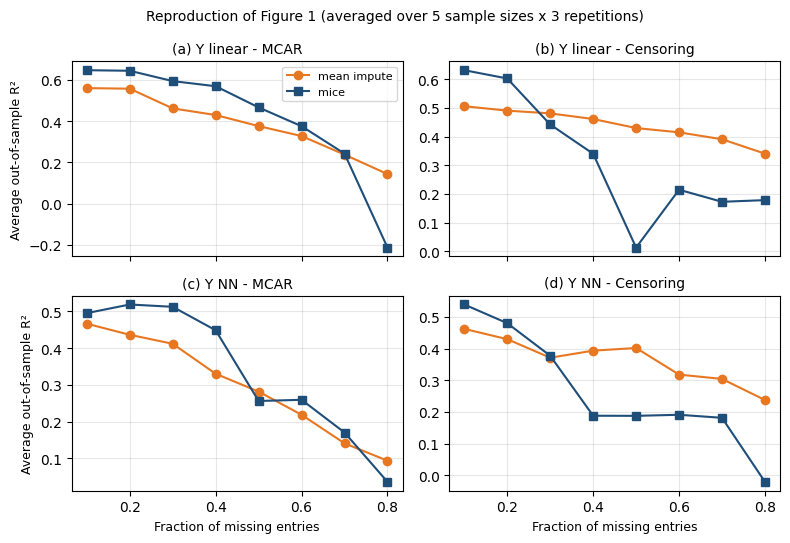

In [0]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(8, 5.5), sharex=True)
panels = [("linear", "MCAR", "(a) Y linear - MCAR"), ("linear", "Censoring", "(b) Y linear - Censoring"),
          ("nn", "MCAR", "(c) Y NN - MCAR"), ("nn", "Censoring", "(d) Y NN - Censoring")]
for ax, (s, m, title) in zip(axes.ravel(), panels):
    g = results[(results.signal == s) & (results.mechanism == m)].groupby("p")[["r2_mean", "r2_mice"]].mean()
    ax.plot(g.index, g["r2_mean"], "o-", label="mean impute", color="#e87722")
    ax.plot(g.index, g["r2_mice"], "s-", label="mice", color="#1f4e79")
    ax.set_title(title, fontsize=10)
    ax.grid(alpha=0.3)
for ax in axes[1]:
    ax.set_xlabel("Fraction of missing entries", fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("Average out-of-sample R\u00b2", fontsize=9)
axes[0, 0].legend(fontsize=8)
fig.suptitle(f"Reproduction of Figure 1 (averaged over {len(N_TRAIN)} sample sizes x {N_REPS} repetitions)", fontsize=10)
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/fig1_reproduction.png", dpi=300, bbox_inches="tight")
print("Saved:", f"{OUT_DIR}/fig1_reproduction.png")
plt.show()

In [0]:
# Numeric check of the Figure 1 pattern: mean R2 per missing fraction and where MICE stops beating mean impute
res = pd.read_csv(f"{OUT_DIR}/results_simple_imputation.csv")
fig1 = (res.groupby(["signal", "mechanism", "p"])[["r2_mean", "r2_mice"]].mean()
           .assign(mice_minus_mean=lambda d: d.r2_mice - d.r2_mean).round(3).reset_index())
display(fig1)

for (s, m), g in fig1.groupby(["signal", "mechanism"], sort=False):
    worse = g.loc[g.mice_minus_mean < 0, "p"]
    print(f"{s:6s} {m:9s}: first missing fraction where MICE < mean impute = "
          f"{worse.min() if len(worse) else 'never'}")

signal,mechanism,p,r2_mean,r2_mice,mice_minus_mean
linear,Censoring,0.1,0.506,0.632,0.126
linear,Censoring,0.2,0.491,0.603,0.112
linear,Censoring,0.3,0.481,0.442,-0.039
linear,Censoring,0.4,0.462,0.34,-0.121
linear,Censoring,0.5,0.43,0.013,-0.417
linear,Censoring,0.6,0.415,0.215,-0.2
linear,Censoring,0.7,0.391,0.173,-0.218
linear,Censoring,0.8,0.341,0.179,-0.162
linear,MCAR,0.1,0.56,0.647,0.087
linear,MCAR,0.2,0.557,0.644,0.087


linear Censoring: first missing fraction where MICE < mean impute = 0.3
linear MCAR     : first missing fraction where MICE < mean impute = 0.8
nn     Censoring: first missing fraction where MICE < mean impute = 0.4
nn     MCAR     : first missing fraction where MICE < mean impute = 0.5
